# End-to-End Sales & Logistics Data Analysis (Python)

## 📌 Project Overview
This project performs a comprehensive commercial, financial, and logistics analysis of **Global Market Company** using **Python (Pandas, Matplotlib, Seaborn)**. By integrating transactional sales data (`events.csv`) with product (`products.csv`) and geographic (`countries.csv`) catalogs, this notebook uncovers actionable insights regarding revenue drivers, profit margins, omnichannel balance, supply chain efficiency, and seasonal demand.


In [13]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# 1. Mount Google Drive and load raw datasets
drive.mount('/content/drive')
folder_path = "/content/drive/MyDrive/Final_project/"

events = pd.read_csv(folder_path + "events.csv")
countries = pd.read_csv(folder_path + "countries.csv")
products = pd.read_csv(folder_path + "products.csv")

print('\n tables loaded successfully!\n ')

print('Columns from events: ', events.columns.tolist())
print('Columns from countries: ', countries.columns.tolist())
print('Columns from products: ', products.columns.tolist())

# 2. Relational Merge (Left Joins to preserve all sales transactions)
df_merged = pd.merge(
    events, products,
    left_on="Product ID",
    right_on="id",
    how="left"
    )

df_global = pd.merge(
    df_merged,
    countries,
    left_on="Country Code",
    right_on="alpha-3",
    how="left"
    )

print("\n Merge completed successfully \n")

# 3. Data Quality Audit & Cleaning
print("Null percentage per column before cleaning:\n", (df_global.isnull().sum() / len(df_global) * 100).round(2))
print(f"\nDuplicated rows found: {df_global.duplicated().sum()}")

# Drop rows with missing 'Units Sold' (negligible 0.16% impact)
df_global = df_global.dropna(subset=["Units Sold"]).copy()

# Fill unmapped country codes as 'Unknown' to maintain geographic integrity
df_global["name"] = df_global["name"].fillna("Unknown")
df_global["region"] = df_global["region"].fillna("Unknown")
df_global["sub-region"] = df_global["sub-region"].fillna("Unknown")

# Standardize text anomalies (whitespace & casing)
df_global["Sales Channel"] = df_global["Sales Channel"].str.strip().str.capitalize()
df_global["Order Priority"] = df_global["Order Priority"].str.strip().str.upper()

# Convert date columns to datetime objects
df_global["Order Date"] = pd.to_datetime(df_global["Order Date"])
df_global["Ship Date"] = pd.to_datetime(df_global["Ship Date"])

# Drop redundant key columns and rename for clarity
df_global = df_global.drop(columns=["id", "alpha-2", "alpha-3"]).rename(
    columns={
        "name": "Country_Name",
        "region": "Region",
        "sub-region": "Sub_Region",
        "item_type": "Product_Category",
    }
)

print("\n✅ Dataset successfully unified, cleaned, and standardized!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

 tables loaded successfully!
 
Columns from events:  ['Order ID', 'Order Date', 'Ship Date', 'Order Priority', 'Country Code', 'Product ID', 'Sales Channel', 'Units Sold', 'Unit Price', 'Unit Cost']
Columns from countries:  ['name', 'alpha-2', 'alpha-3', 'region', 'sub-region']
Columns from products:  ['id', 'item_type']

 Merge completed successfully 

Null percentage per column before cleaning:
 Order ID          0.00
Order Date        0.00
Ship Date         0.00
Order Priority    0.00
Country Code      6.17
Product ID        0.00
Sales Channel     0.00
Units Sold        0.15
Unit Price        0.00
Unit Cost         0.00
id                0.00
item_type         0.00
name              6.17
alpha-2           6.17
alpha-3           6.17
region            6.17
sub-region        6.17
dtype: float64

Duplicated rows found: 0

✅ Dataset successfully unified, clea

In [14]:
# 4. Financial & Logistics Feature Engineering
df_global["days_to_ship"] = (df_global["Ship Date"] - df_global["Order Date"]).dt.days
df_global["Total Revenue"] = df_global["Units Sold"] * df_global["Unit Price"]
df_global["Total Cost"] = df_global["Units Sold"] * df_global["Unit Cost"]
df_global["Profit"] = df_global["Total Revenue"] - df_global["Total Cost"]
df_global["Year_Month"] = df_global["Order Date"].dt.to_period("M")
df_global["Day_of_Week"] = df_global["Order Date"].dt.day_name()

# Executive KPIs Summary
total_orders = df_global["Order ID"].nunique()
total_revenue = df_global["Total Revenue"].sum()
total_cost = df_global["Total Cost"].sum()
total_profit = df_global["Profit"].sum()
profit_margin = (total_profit / total_revenue) * 100
total_countries = df_global[df_global["Country_Name"] != "Unknown"]["Country_Name"].nunique()

print("==========================================")
print("       EXECUTIVE FINANCIAL SUMMARY        ")
print("==========================================")
print(f"Total Orders:      {total_orders:,}")
print(f"Covered Countries: {total_countries}")
print(f"Total Revenue:     ${total_revenue:,.2f}")
print(f"Total Cost:        ${total_cost:,.2f}")
print(f"Total Net Profit:  ${total_profit:,.2f}")
print(f"Global Margin:     {profit_margin:.2f}%")
print("==========================================")

       EXECUTIVE FINANCIAL SUMMARY        
Total Orders:      1,328
Covered Countries: 45
Total Revenue:     $1,702,129,408.21
Total Cost:        $1,200,694,949.21
Total Net Profit:  $501,434,459.00
Global Margin:     29.46%


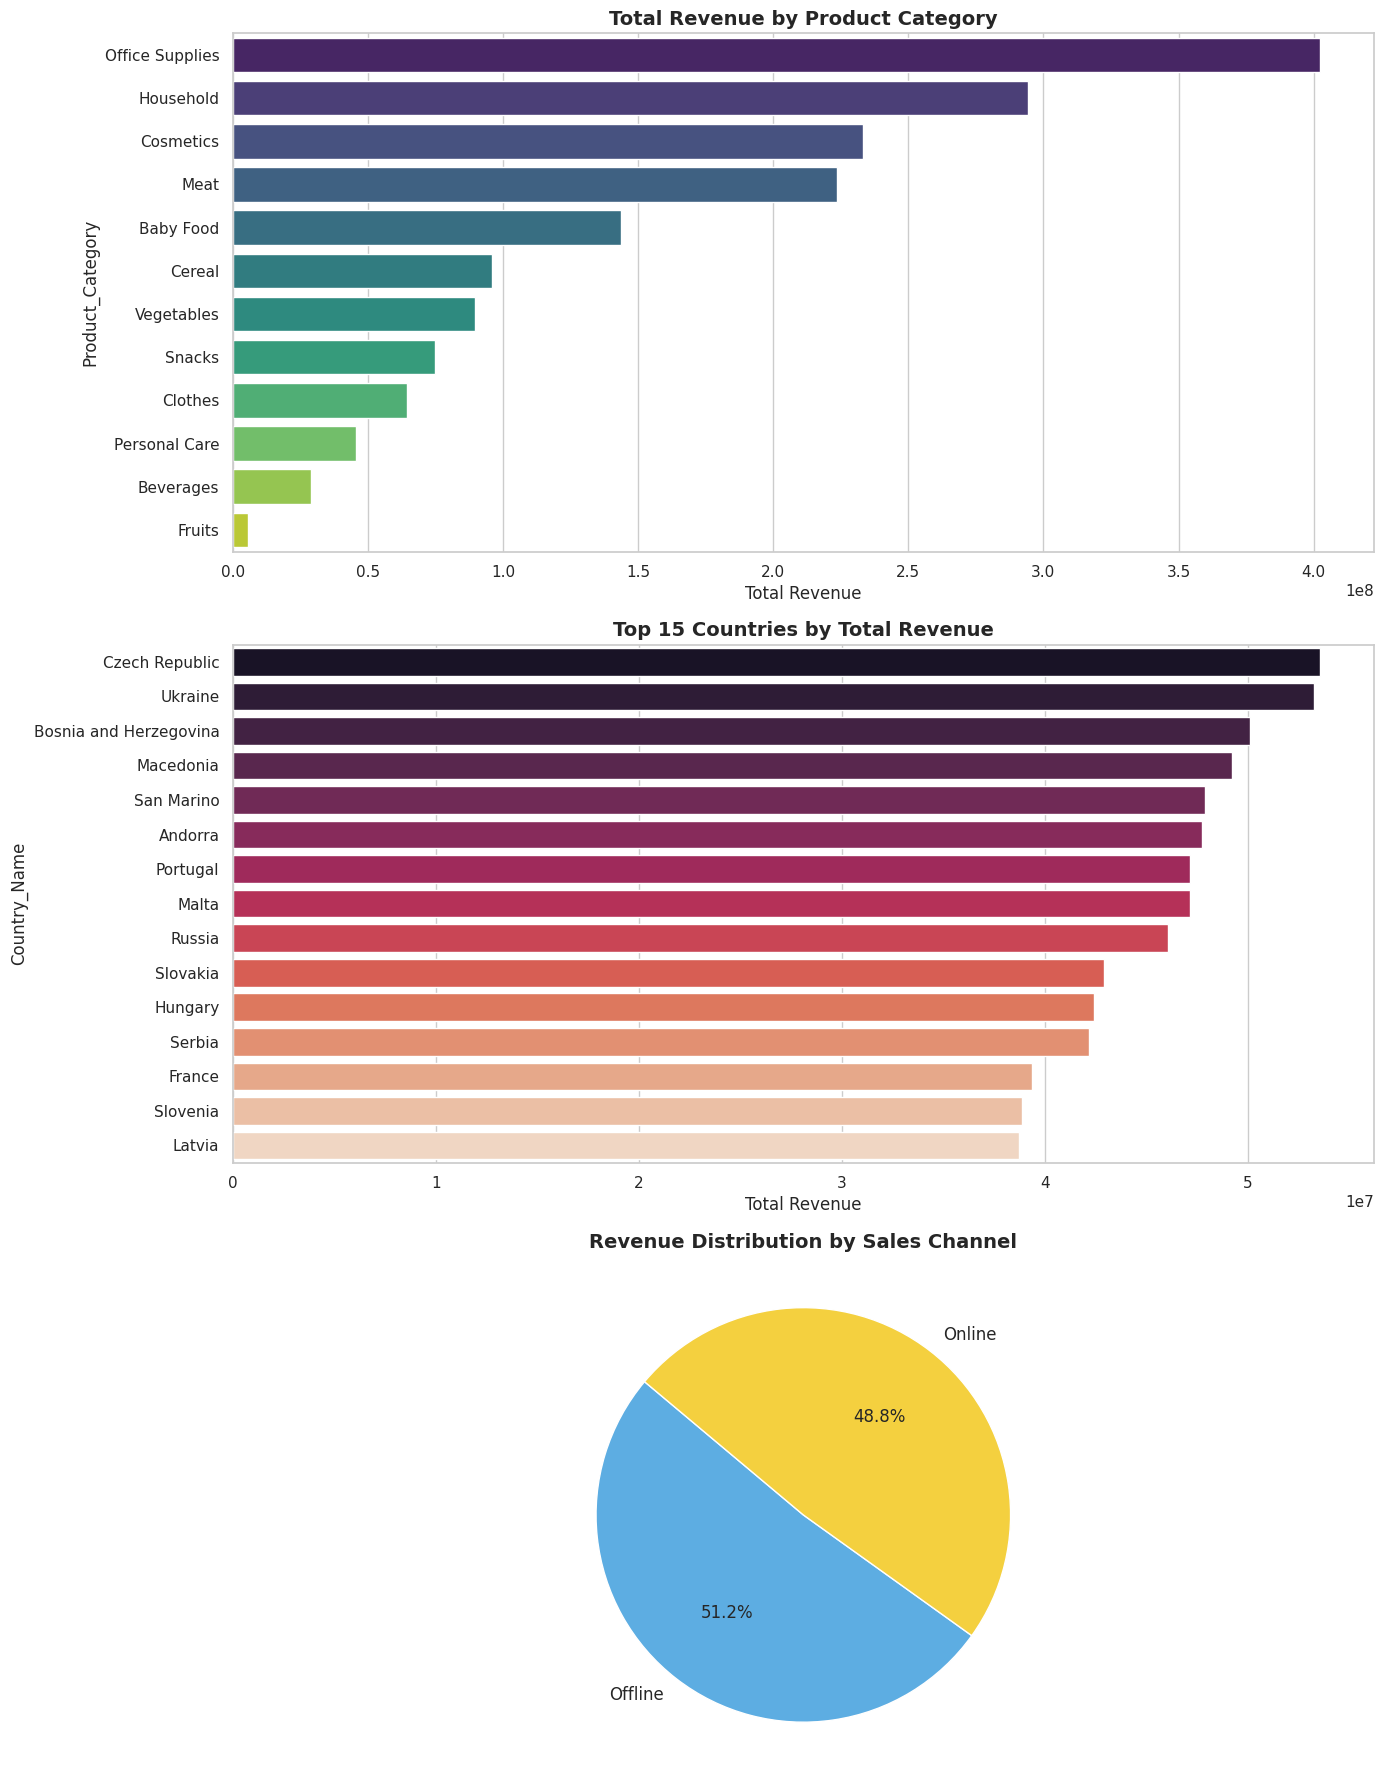

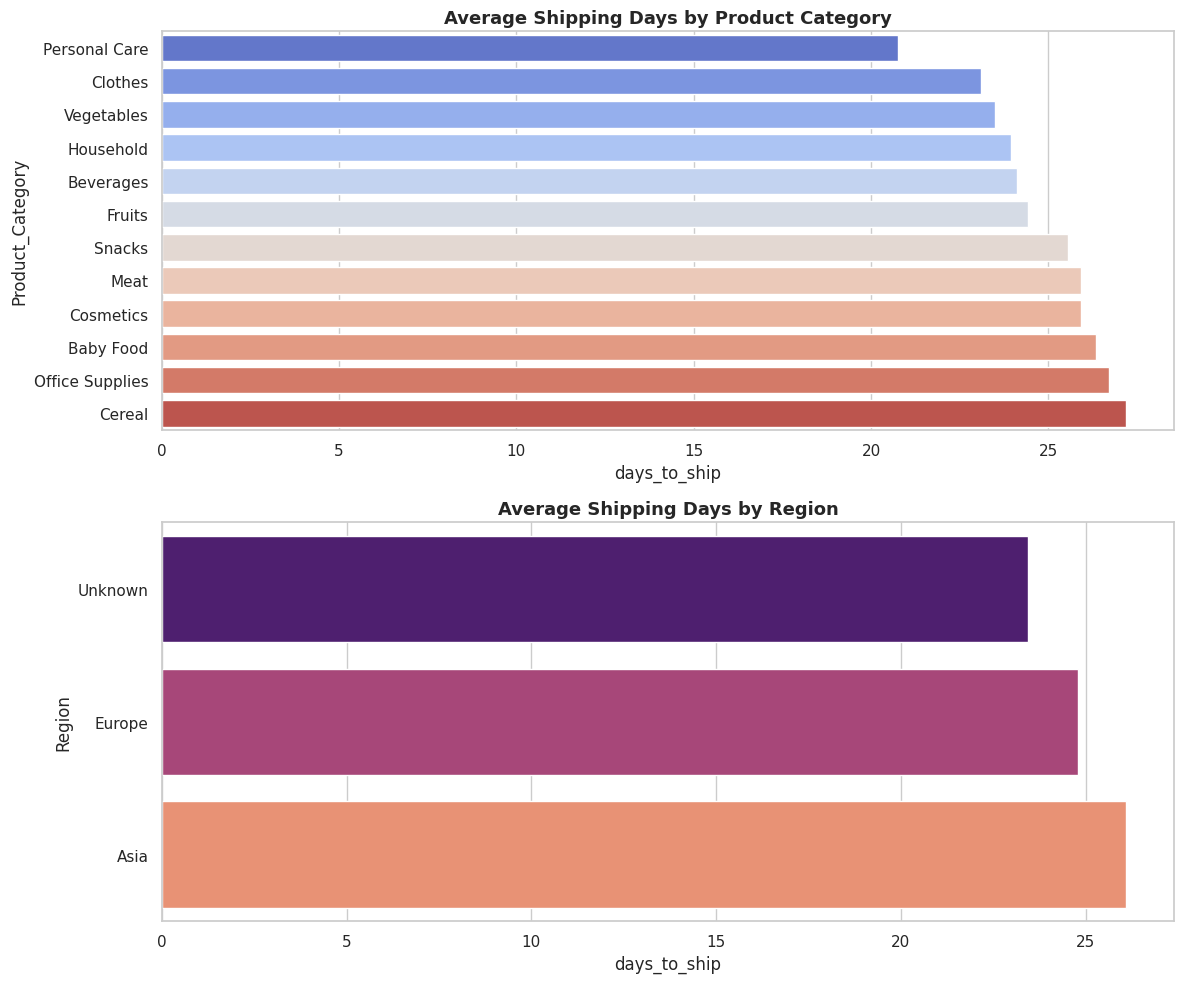

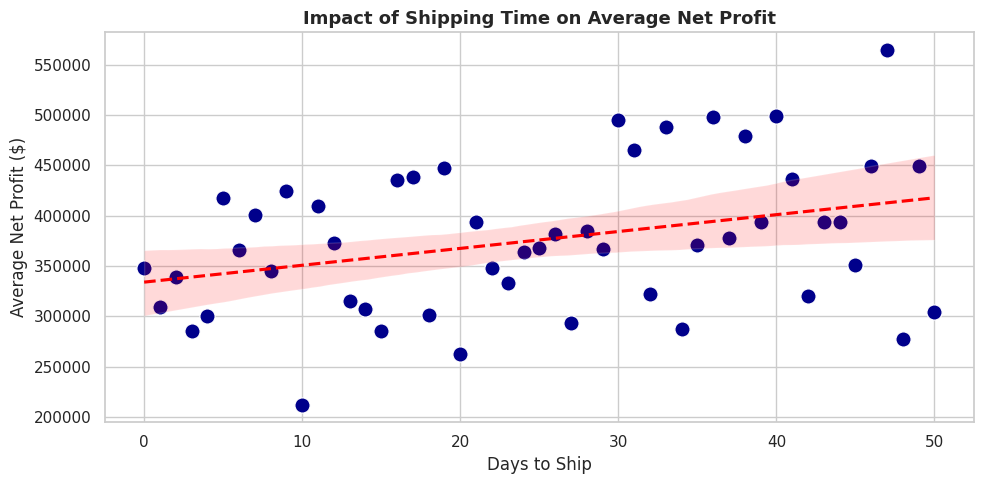

In [15]:
sns.set_theme(style="whitegrid")

# --- CHART 1: Revenue by Category, Top 15 Countries & Sales Channel ---
fig, axes = plt.subplots(3, 1, figsize=(14, 18))

cat_data = df_global.groupby("Product_Category")["Total Revenue"].sum().sort_values(ascending=False).reset_index()
sns.barplot(ax=axes[0], data=cat_data, x="Total Revenue", y="Product_Category", hue="Product_Category", palette="viridis", legend=False)
axes[0].set_title("Total Revenue by Product Category", fontsize=14, fontweight="bold")

geo_data = df_global[df_global["Country_Name"] != "Unknown"].groupby("Country_Name")["Total Revenue"].sum().sort_values(ascending=False).head(15).reset_index()
sns.barplot(ax=axes[1], data=geo_data, x="Total Revenue", y="Country_Name", hue="Country_Name", palette="rocket", legend=False)
axes[1].set_title("Top 15 Countries by Total Revenue", fontsize=14, fontweight="bold")

channel_data = df_global.groupby("Sales Channel")["Total Revenue"].sum().reset_index()
axes[2].pie(channel_data["Total Revenue"], labels=channel_data["Sales Channel"], autopct="%1.1f%%", colors=["#5DADE2", "#F4D03F"], startangle=140, textprops={"fontsize": 12})
axes[2].set_title("Revenue Distribution by Sales Channel", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

# --- CHART 2: Logistics & Average Shipping Time ---
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

cat_ship = df_global.groupby("Product_Category")["days_to_ship"].mean().sort_values().reset_index()
sns.barplot(ax=axes[0], data=cat_ship, x="days_to_ship", y="Product_Category", hue="Product_Category", palette="coolwarm", legend=False)
axes[0].set_title("Average Shipping Days by Product Category", fontsize=13, fontweight="bold")

region_ship = df_global.groupby("Region")["days_to_ship"].mean().sort_values().reset_index()
sns.barplot(ax=axes[1], data=region_ship, x="days_to_ship", y="Region", hue="Region", palette="magma", legend=False)
axes[1].set_title("Average Shipping Days by Region", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

# --- CHART 3: Logistics Impact on Net Profit (Fixed regplot syntax) ---
ship_profit_relation = df_global.groupby("days_to_ship")["Profit"].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.scatterplot(data=ship_profit_relation, x="days_to_ship", y="Profit", s=120, color="darkblue")
sns.regplot(
    data=ship_profit_relation,
    x="days_to_ship",
    y="Profit",
    scatter=False,
    color="red",
    line_kws={"linestyle": "--"},
)
plt.title("Impact of Shipping Time on Average Net Profit", fontsize=13, fontweight="bold")
plt.xlabel("Days to Ship")
plt.ylabel("Average Net Profit ($)")
plt.tight_layout()
plt.show()


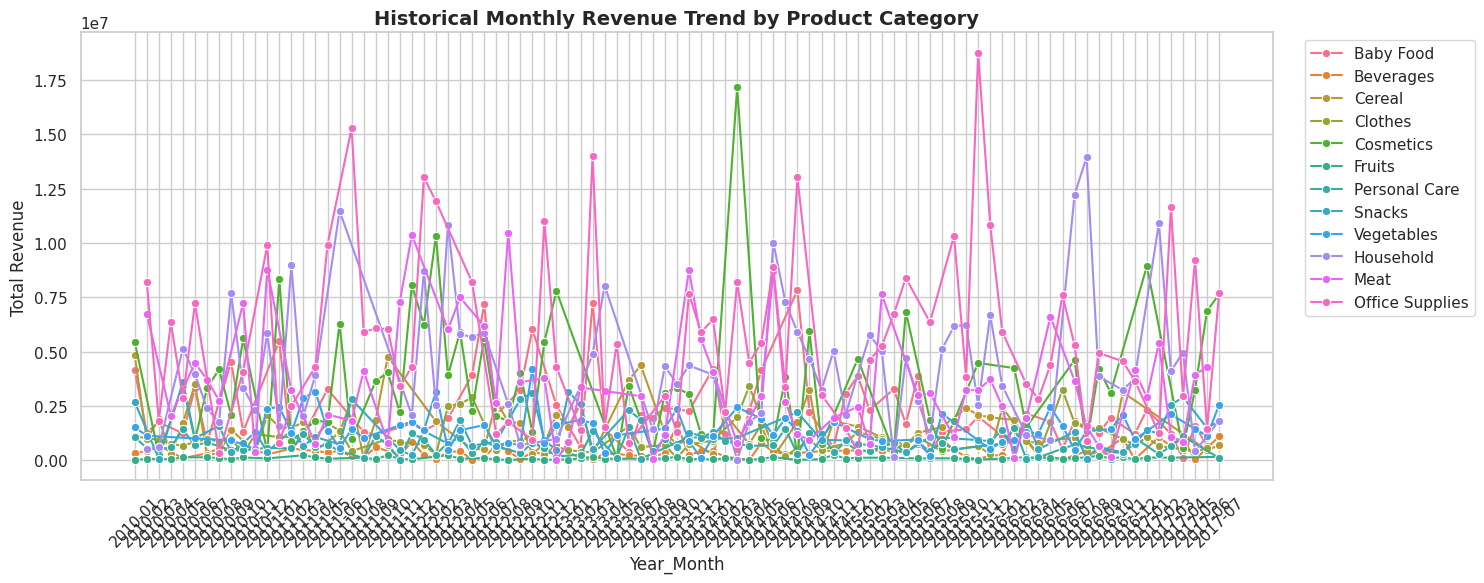

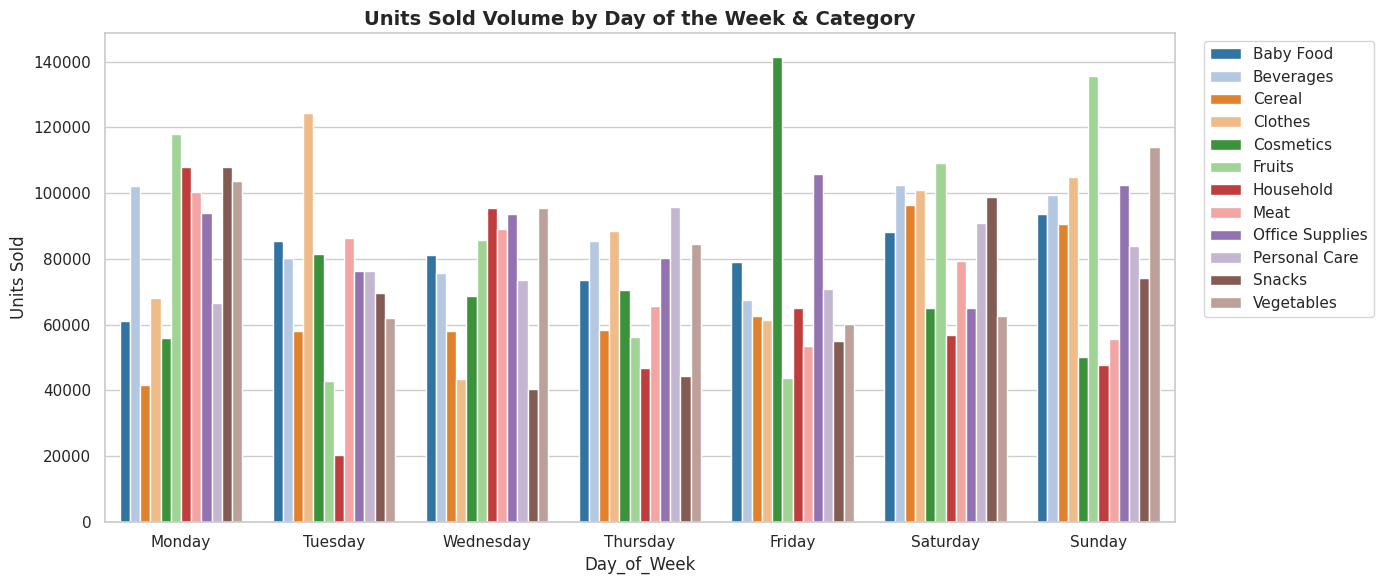

In [16]:
# --- CHART 4: Monthly Historical Revenue Trend by Category ---
time_data = df_global.groupby(["Year_Month", "Product_Category"])["Total Revenue"].sum().reset_index()
time_data["Year_Month"] = time_data["Year_Month"].astype(str)

plt.figure(figsize=(15, 6))
sns.lineplot(data=time_data, x="Year_Month", y="Total Revenue", hue="Product_Category", marker="o")
plt.title("Historical Monthly Revenue Trend by Product Category", fontsize=14, fontweight="bold")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# --- CHART 5: Sales Volume by Day of the Week ---
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekly_sales = df_global.groupby(["Day_of_Week", "Product_Category"])["Units Sold"].sum().reset_index()

plt.figure(figsize=(14, 6))
sns.barplot(data=weekly_sales, x="Day_of_Week", y="Units Sold", hue="Product_Category", order=days_order, palette="tab20")
plt.title("Units Sold Volume by Day of the Week & Category", fontsize=14, fontweight="bold")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 📈 Key Business & Analytical Conclusions

### 1. Data Quality & Integrity
* **Missing Values:** Only **0.16%** of records lacked `Units Sold` values; removing them preserved statistical accuracy without introducing bias.
* **Text Standardization:** Normalized casing and trailing spaces in `Sales Channel` (`Online` vs. `online`) and `Order Priority` (`' C'`, `'M '`), preventing artificial category duplication.

### 2. Commercial & Omnichannel Performance
* **Balanced Revenue Streams:** Online and Offline channels exhibit an almost **50/50 revenue split**, confirming a healthy omnichannel strategy.
* **Core Markets:** Identifying the Top 15 revenue-generating countries provides a clear roadmap for prioritizing marketing budgets and regional inventory allocation.

### 3. Supply Chain & Logistics Efficiency
* **Profitability Resilience:** The regression trend between `days_to_ship` and `Profit` remains flat, demonstrating that longer delivery windows do not erode net profit margins per order.
* **Bottleneck Detection:** Regional and category-level shipping averages pinpoint specific logistics nodes where operational audits can reduce transit times.

### 4. Temporal Trends & Weekly Seasonality
* **Demand Scheduling:** Analyzing sales by `Day_of_Week` reveals distinct purchasing spikes across product categories, enabling data-driven **inventory restocking** and targeted digital ad scheduling on high-conversion days.
